# EDA 2: Default of Credit Card Clients
**Source:** UCI Machine Learning Repository, https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients
(downloaded here through OpenML, dataset id 42477, which is the same data in a format scikit-learn can read without extra packages)


This dataset (Yeh & Lien, 2009) has 30,000 credit card clients in Taiwan from 2005. For each client it
records the credit limit, some demographics, and six months of repayment status, bill amounts and payments.
The task is to predict whether the client defaults on the next payment. TabDDPM (Kotelnikov et al., 2023) and TabSyn (Zhang et al., 2024) both use it as a benchmark (called "Default" there).

Why it is interesting for synthetic data:
- most columns are financial amounts with very long tails, some of them negative
- the six monthly columns are strongly correlated with each other (a time structure inside one row)
- some categorical codes appear in the data but are not explained in the documentation
- the target is imbalanced

**What this notebook produces:** a summary row for the report table, figures in `figures/eda/`



## 1. Setup

Imports, folder paths and plot settings. The notebook works whether you open it from the repo root
or from the `notebooks/` folder, because the root folder is worked out from the current directory.

Outputs go to three folders (created if they don't exist):

- `data/raw/`: a local copy of the downloaded data, so the download only happens once
- `figures/eda/`: PNG figures for the report
- `results/eda/`: the summary table as a CSV

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Find the repo root (this notebook lives in notebooks/)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_DIR = ROOT / "data" / "raw"
FIG_DIR = ROOT / "figures" / "eda"
RES_DIR = ROOT / "results" / "eda"
for folder in (RAW_DIR, FIG_DIR, RES_DIR):
    folder.mkdir(parents=True, exist_ok=True)

# Plot style: one blue for single-colour plots, blue/orange for the two classes
BLUE, ORANGE = "#2a78d6", "#eb6834"
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["savefig.dpi"] = 200
plt.rcParams["savefig.bbox"] = "tight"
pd.set_option("display.max_columns", 50)

print("Repo root:", ROOT)

Repo root: c:\Users\Admin\OneDrive\Desktop\MS DS 1\DS lab 1\EDA & Milestone 1\dslab1_synthetic_data


## 2. Load the data

The original UCI file is an Excel `.xls` file, which needs an extra package (`xlrd`). OpenML hosts the
same table, and `sklearn.datasets.fetch_openml` can download it directly. On OpenML the columns are called `x1` ... `x23` and `y`, so we give them the original UCI names.

(`PAY_1` does not exist in the original file. The first repayment column is called `PAY_0`. We keep the
original names so they match other papers and code.)

If the download fails, download the `.xls` from the UCI page, read it with
`pd.read_excel(path, header=1)`, drop the `ID` column, and save it as `data/raw/credit_default.csv`.
The notebook will pick up that file instead.

In [2]:
from sklearn.datasets import fetch_openml

CREDIT_COLUMNS = (
    ["LIMIT_BAL", "SEX", "EDUCATION", "MARRIAGE", "AGE"]
    + ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
    + [f"BILL_AMT{i}" for i in range(1, 7)]
    + [f"PAY_AMT{i}" for i in range(1, 7)]
    + ["default"]
)
cache_file = RAW_DIR / "credit_default.csv"

if cache_file.exists():
    df = pd.read_csv(cache_file)
    print("Loaded local copy:", cache_file)
else:
    raw = fetch_openml(data_id=42477, as_frame=True, parser="auto").frame
    # drop an ID column if there is one, then rename by position
    raw = raw.loc[:, [c for c in raw.columns if c.lower() != "id"]]
    assert raw.shape[1] == len(CREDIT_COLUMNS), f"Expected 24 columns, got {raw.shape[1]}"
    raw.columns = CREDIT_COLUMNS
    # OpenML may store some columns as 'category'; everything in this dataset is a number
    df = raw.apply(lambda col: pd.to_numeric(col.astype(str))).astype("int64")
    df.to_csv(cache_file, index=False)
    print("Downloaded from OpenML and saved to", cache_file)

print("Shape:", df.shape)
df.head()

Downloaded from OpenML and saved to c:\Users\Admin\OneDrive\Desktop\MS DS 1\DS lab 1\EDA & Milestone 1\dslab1_synthetic_data\data\raw\credit_default.csv
Shape: (30000, 24)


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default
0,20000,2,2,1,24,2,2,-1,-1,-2,-2,3913,3102,689,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,2,2682,1725,2682,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,0,29239,14027,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,50000,2,2,1,37,0,0,0,0,0,0,46990,48233,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,50000,1,2,1,57,-1,0,-1,0,0,0,8617,5670,35835,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [3]:
# Quick check that the renaming is right: SEX should only be 1/2, AGE between ~20 and ~80, and the target only 0/1.
print("SEX values:", sorted(df["SEX"].unique()))
print("AGE range:", df["AGE"].min(), "-", df["AGE"].max())
print("default values:", sorted(df["default"].unique()))

SEX values: [np.int64(1), np.int64(2)]
AGE range: 21 - 79
default values: [np.int64(0), np.int64(1)]


## 3. Column types

Every column is stored as an integer, but they are not all the same kind of variable:

- **Categorical (nominal):** `SEX`, `EDUCATION`, `MARRIAGE`. The numbers are just codes.
- **Ordinal:** `PAY_0` ... `PAY_6`. Higher means more months of delay, so the order means something.
- **Numeric:** `LIMIT_BAL`, `AGE`, the six `BILL_AMT` and the six `PAY_AMT` columns.

This choice affects how generators treat the columns. For the report table we count the ordinal `PAY_`
columns as numeric (they are ordered integers), which gives 20 numeric and 3 categorical features.
This is a decision to revisit in M2: if a generator treats `PAY_0` as continuous, it may produce values which are not valid codes.

In [4]:
TARGET = "default"
cat_cols = ["SEX", "EDUCATION", "MARRIAGE"]
pay_cols = ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
bill_cols = [f"BILL_AMT{i}" for i in range(1, 7)]
payamt_cols = [f"PAY_AMT{i}" for i in range(1, 7)]
num_cols = ["LIMIT_BAL", "AGE"] + pay_cols + bill_cols + payamt_cols

print(len(num_cols), "numeric (incl. ordinal PAY_ columns),", len(cat_cols), "categorical")

20 numeric (incl. ordinal PAY_ columns), 3 categorical


## 4. Missing values and undocumented codes

There are no empty cells in this dataset, but there are codes that the documentation does not explain.
According to the UCI description:

- `EDUCATION`: 1 = graduate school, 2 = university, 3 = high school, 4 = others
- `MARRIAGE`: 1 = married, 2 = single, 3 = others
- `PAY_x`: -1 = paid duly, 1 = one month delay, 2 = two months delay, ... 9 = nine or more months

Checking the values:

In [5]:
print("Empty cells in the whole table:", int(df.isna().sum().sum()))
print()
print("EDUCATION:", df["EDUCATION"].value_counts().sort_index().to_dict())
print("MARRIAGE: ", df["MARRIAGE"].value_counts().sort_index().to_dict())
print("PAY_0:    ", df["PAY_0"].value_counts().sort_index().to_dict())

Empty cells in the whole table: 0

EDUCATION: {0: 14, 1: 10585, 2: 14030, 3: 4917, 4: 123, 5: 280, 6: 51}
MARRIAGE:  {0: 54, 1: 13659, 2: 15964, 3: 323}
PAY_0:     {-2: 2759, -1: 5686, 0: 14737, 1: 3688, 2: 2667, 3: 322, 4: 76, 5: 26, 6: 11, 7: 9, 8: 19}


In [6]:
undocumented = {
    "EDUCATION in {0, 5, 6}": df["EDUCATION"].isin([0, 5, 6]).sum(),
    "MARRIAGE == 0": (df["MARRIAGE"] == 0).sum(),
    "PAY_0 in {-2, 0}": df["PAY_0"].isin([-2, 0]).sum(),
}
pd.Series(undocumented, name="rows")

EDUCATION in {0, 5, 6}      345
MARRIAGE == 0                54
PAY_0 in {-2, 0}          17496
Name: rows, dtype: int64

- `EDUCATION` has the values 0, 5 and 6, and `MARRIAGE` has 0. None of these are in the documentation.
  They are few rows, so they are rare categories, which is exactly what generators tend to drop.
- `PAY_x` uses -2 and 0, which are also not documented. They are very common though, so they cannot be
  dropped. A common reading is -2 = no credit used, 0 = revolving credit (minimum payment made). We keep the
  values as they are.

## 5. Class balance

         count  share
default              
0        23364  0.779
1         6636  0.221


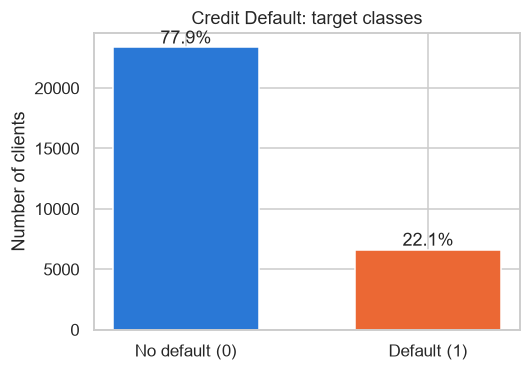

In [7]:
counts = df[TARGET].value_counts().sort_index()
shares = df[TARGET].value_counts(normalize=True).sort_index()
print(pd.DataFrame({"count": counts, "share": shares.round(3)}))

fig, ax = plt.subplots(figsize=(5, 3.5))
labels = ["No default (0)", "Default (1)"]
bars = ax.bar(labels, counts.values, color=[BLUE, ORANGE], width=0.6)
for bar, share in zip(bars, shares.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f"{share:.1%}",
            ha="center", va="bottom")
ax.set_title("Credit Default: target classes")
ax.set_ylabel("Number of clients")
fig.savefig(FIG_DIR / "credit_class_balance.png")
plt.show()

## 6. Numeric columns

The amount columns are the main challenge here. Look at the summary statistics: skewness, how many values
are exactly zero, and how many are negative.

In [8]:
amount_cols = ["LIMIT_BAL", "AGE"] + bill_cols + payamt_cols
stats = df[amount_cols].describe().T
stats["skew"] = df[amount_cols].skew()
stats["share_zero"] = (df[amount_cols] == 0).mean()
stats["share_negative"] = (df[amount_cols] < 0).mean()
stats.round(2)

,count,mean,std,min,25%,50%,75%,max,skew,share_zero,share_negative
LIMIT_BAL,30000.0,167484.32,129747.66,10000.0,50000.00,140000.0,240000.00,1000000.0,0.99,0.00,0.00
AGE,30000.0,35.49,9.22,21.0,28.00,34.0,41.00,79.0,0.73,0.00,0.00
BILL_AMT1,30000.0,51223.33,73635.86,-165580.0,3558.75,22381.5,67091.00,964511.0,2.66,0.07,0.02
BILL_AMT2,30000.0,49179.08,71173.77,-69777.0,2984.75,21200.0,64006.25,983931.0,2.71,0.08,0.02
BILL_AMT3,30000.0,47013.15,69349.39,-157264.0,2666.25,20088.5,60164.75,1664089.0,3.09,0.10,0.02
BILL_AMT4,30000.0,43262.95,64332.86,-170000.0,2326.75,19052.0,54506.00,891586.0,2.82,0.11,0.02
BILL_AMT5,30000.0,40311.40,60797.16,-81334.0,1763.00,18104.5,50190.50,927171.0,2.88,0.12,0.02
BILL_AMT6,30000.0,38871.76,59554.11,-339603.0,1256.00,17071.0,49198.25,961664.0,2.85,0.13,0.02
PAY_AMT1,30000.0,5663.58,16563.28,0.0,1000.00,2100.0,5006.00,873552.0,14.67,0.17,0.00
PAY_AMT2,30000.0,5921.16,23040.87,0.0,833.00,2009.0,5000.00,1684259.0,30.45,0.18,0.00


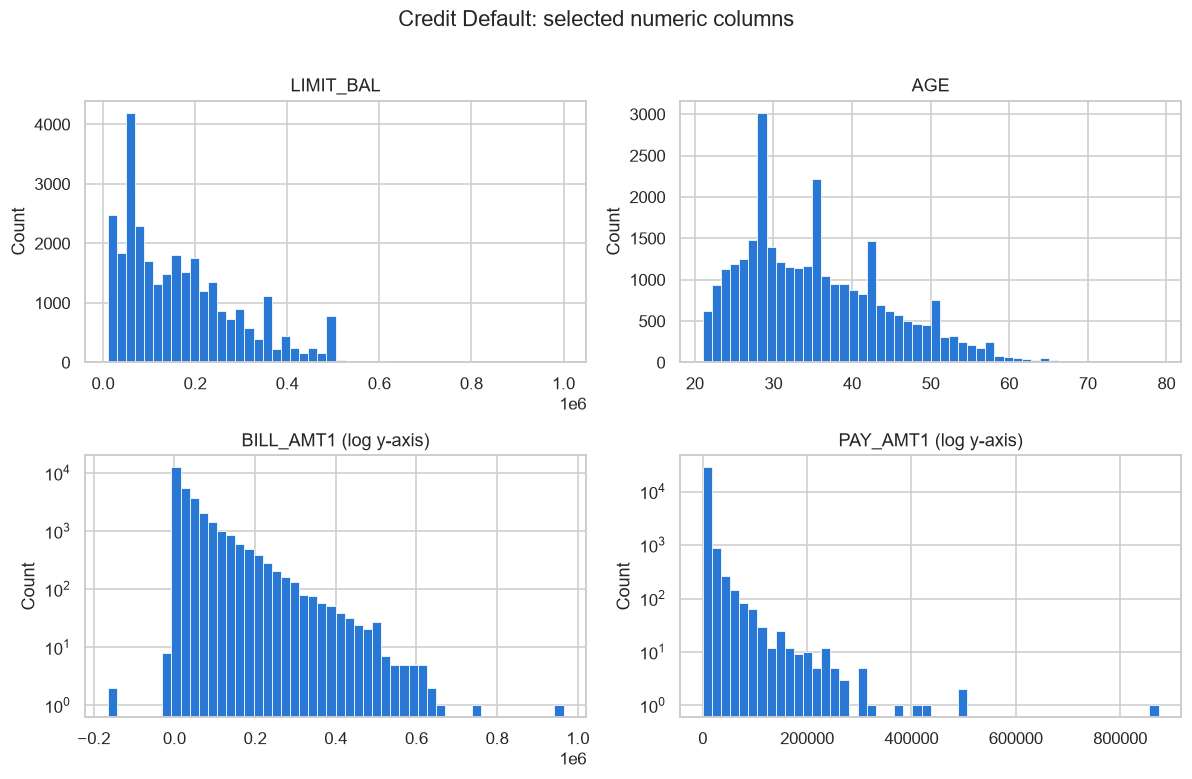

In [9]:
# Four representative columns. For the two amount columns the y-axis is logarithmic
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, col in zip(axes.ravel(), ["LIMIT_BAL", "AGE", "BILL_AMT1", "PAY_AMT1"]):
    ax.hist(df[col], bins=50, color=BLUE, edgecolor="white", linewidth=0.5)
    ax.set_title(col)
    ax.set_ylabel("Count")
    if col in ("BILL_AMT1", "PAY_AMT1"):
        ax.set_yscale("log")
        ax.set_title(col + " (log y-axis)")
fig.suptitle("Credit Default: selected numeric columns", y=1.01)
fig.tight_layout()
fig.savefig(FIG_DIR / "credit_numeric_distributions.png")
plt.show()

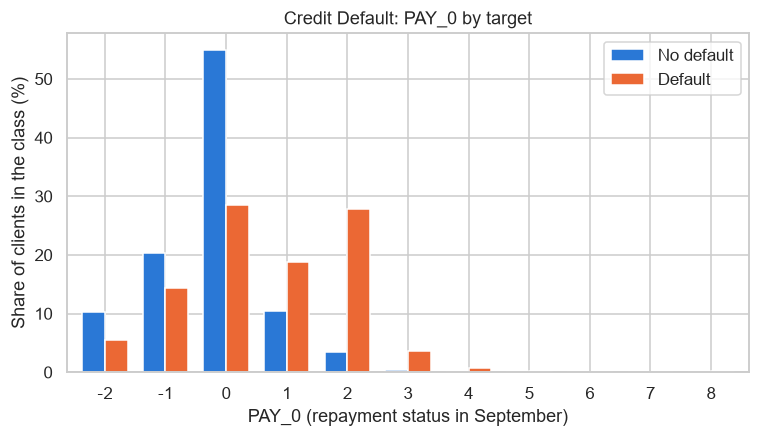

In [10]:
# Repayment status for the most recent month, split by the target
pay0 = pd.crosstab(df["PAY_0"], df[TARGET], normalize="columns") * 100

fig, ax = plt.subplots(figsize=(8, 4))
pay0.plot(kind="bar", ax=ax, color=[BLUE, ORANGE], width=0.75)
ax.set_xlabel("PAY_0 (repayment status in September)")
ax.set_ylabel("Share of clients in the class (%)")
ax.set_title("Credit Default: PAY_0 by target")
ax.legend(["No default", "Default"])
ax.tick_params(axis="x", rotation=0)
fig.savefig(FIG_DIR / "credit_pay0_by_target.png")
plt.show()

What stands out:
- `BILL_AMT` and `PAY_AMT` are very right-skewed, and a large share of the payments are exactly zero.
  `BILL_AMT` also has negative values (credit balance), so a log transform alone will not work.
- `LIMIT_BAL` takes round values (multiples of 10,000), so it is closer to a discrete column than a
  continuous one. A generator that outputs 123,457 is technically "wrong" here.
- `PAY_0` is the most informative column for the target: clients with a delay of 2 months or more default
  much more often.

## 7. Relationships between columns

The six monthly columns of each group (bills, payments, repayment status) should be strongly correlated,
because the same client tends to have similar bills from month to month. Spearman correlation is used
because of the long tails.

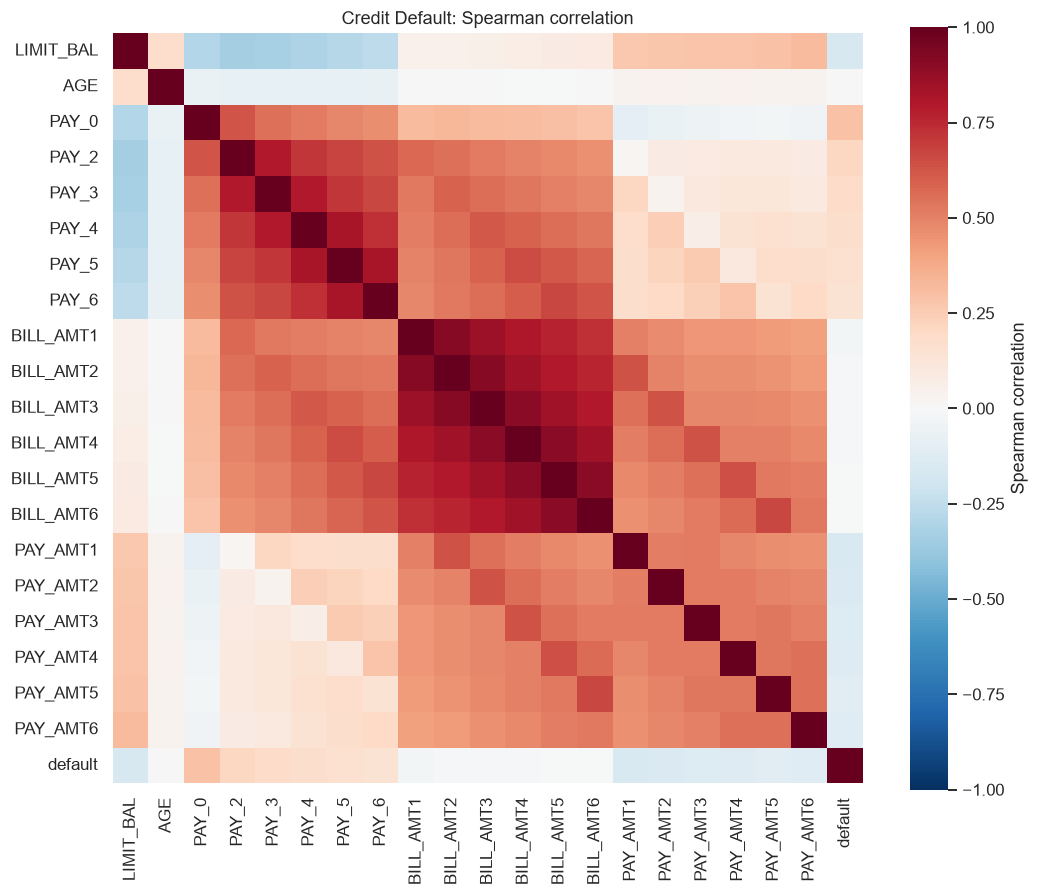

In [11]:
spearman = df[num_cols + [TARGET]].corr(method="spearman")

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(spearman, cmap="RdBu_r", vmin=-1, vmax=1, square=True, ax=ax,
            cbar_kws={"label": "Spearman correlation"})
ax.set_title("Credit Default: Spearman correlation")
fig.savefig(FIG_DIR / "credit_spearman.png")
plt.show()

In [12]:
# Average correlation inside each block of six monthly columns
def mean_offdiag(cols):
    block = spearman.loc[cols, cols].to_numpy()
    return block[~np.eye(len(cols), dtype=bool)].mean()

print("Mean correlation within BILL_AMT1-6:", round(mean_offdiag(bill_cols), 2))
print("Mean correlation within PAY_AMT1-6: ", round(mean_offdiag(payamt_cols), 2))
print("Mean correlation within PAY_0-6:    ", round(mean_offdiag(pay_cols), 2))
print()
print("Correlation with the target (top 5):")
print(spearman[TARGET].drop(TARGET).abs().sort_values(ascending=False).head(5).round(2))

Mean correlation within BILL_AMT1-6: 0.84
Mean correlation within PAY_AMT1-6:  0.51
Mean correlation within PAY_0-6:     0.67

Correlation with the target (top 5):
PAY_0        0.29
PAY_2        0.22
PAY_3        0.19
PAY_4        0.17
LIMIT_BAL    0.17
Name: default, dtype: float64


In [13]:
from scipy.stats import chi2_contingency


def cramers_v(x, y):
    """Cramér's V between two categorical columns (0 = no association, 1 = perfect)."""
    table = pd.crosstab(x, y)
    chi2 = chi2_contingency(table, correction=False)[0]
    n = table.to_numpy().sum()
    r, k = table.shape
    return np.sqrt(chi2 / (n * (min(r, k) - 1)))

In [14]:
cat_and_target = cat_cols + [TARGET]
cramers = pd.DataFrame(index=cat_and_target, columns=cat_and_target, dtype=float)
for a in cat_and_target:
    for b in cat_and_target:
        cramers.loc[a, b] = cramers_v(df[a], df[b])
cramers.round(3)

,SEX,EDUCATION,MARRIAGE,default
SEX,1.000,0.032,0.033,0.040
EDUCATION,0.032,1.000,0.115,0.074
MARRIAGE,0.033,0.115,1.000,0.034
default,0.040,0.074,0.034,1.000


The block of `BILL_AMT` columns is the clearest dependency in the dataset. It is a good test for RQ2
(dependencies): a generator that models each column on its own will lose this block structure even if
each single column looks right. The demographic columns are only weakly related to each other and to the
target.

## 8. Duplicate rows

In [15]:
n_dup = df.duplicated().sum()
print(f"Exact duplicate rows: {n_dup} ({n_dup / len(df):.2%})")

Exact duplicate rows: 35 (0.12%)


## 9. Summary for the report

`Cols` counts all columns including the target (the `ID` column is not included).

In [16]:
summary = pd.DataFrame([{
    "dataset": "Default of Credit Card Clients",
    "rows": len(df),
    "cols": df.shape[1],
    "numeric": len(num_cols),
    "categorical": len(cat_cols),
    "target": "default (0/1)",
    "minority_share": round(df[TARGET].value_counts(normalize=True).min(), 3),
    "rows_with_missing": int(df.isna().any(axis=1).sum()),
    "missing_note": "none; undocumented codes in EDUCATION, MARRIAGE, PAY_x",
}])
summary.to_csv(RES_DIR / "credit_summary.csv", index=False)

s = summary.iloc[0]
print(f"Default of Credit Card Clients & {s.rows:,} & {s.cols} & {s.numeric} & {s.categorical} & "
      f"default (0/1) & none (undocumented codes) \\\\")
summary

Default of Credit Card Clients & 30,000 & 24 & 20 & 3 & default (0/1) & none (undocumented codes) \\


,dataset,rows,cols,numeric,categorical,target,minority_share,rows_with_missing,missing_note
0,Default of Credit Card Clients,30000,24,20,3,default (0/1),0.221,0,"none; undocumented codes in EDUCATION, MARRIAG..."
